# Laboratorio 9: Quantum Computing — Oscilaciones de Rabi




## Exercise 1: $NH_3$ molecule

An example of the quantum oscillations in two-level systems may be rather unexpected; for example, the ammonium molecule 

![NH3](../Sesiones/QC/figures/NH3.png)
![NH3](NH3.png)

 It has two symmetric states that differ by the inversion of the nitrogen atom relative to the plane of the three hydrogen atoms, which are weakly coupled due to quantum-mechanical tunneling of the nitrogen atom through the plane of the hydrogen atoms. Since for this particular molecule, in the absence of external fields, the level splitting $\Delta E$ corresponds to an experimentally convenient frequency $\Omega/2\pi\approx$ 24.79 GHz.

 1. Supose a detuning frequency $\Omega_R/2$.
 2. Compute the Rabi frequency for NH3 molecule in Hz and do a plot of the Rabi oscillation. Supose that the initial state is $\ket{2}$.
 
 [see](https://phys.libretexts.org/Bookshelves/Quantum_Mechanics/Essential_Graduate_Physics_-_Quantum_Mechanics_(Likharev)/05%3A_Some_Exactly_Solvable_Problems/5.01%3A_Two-level_Systems)

### Constantes y datos del problema

Para el NH$_3$ se toma el valor experimental $\Omega/2\pi \approx 24.79$ GHz. En ausencia de campo externo la desintonización es cero, de modo que $\Omega=\Omega_R$; por tanto, la frecuencia de Rabi es $f_R=\Omega_R/2\pi=24.79$ GHz.


In [1]:
# ============================================================
# Librerías y constantes físicas
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    'figure.dpi': 110,
    'font.size': 10,
    'axes.grid': True,
    'grid.alpha': 0.3,
})

h = 6.62607015e-34          # constante de Planck [J s]
hbar = h / (2 * np.pi)      # constante reducida [J s]
eV = 1.602176634e-19        # 1 eV en julios

f_split = 24.79e9           # ΔE/h para el NH3 [Hz]


### 1. Frecuencia de Rabi y desintonización

Se calcula primero la frecuencia de Rabi angular $\Omega_R=2\pi f_R$. Luego se impone la desintonización pedida, $\Delta=\Omega_R/2$, y se obtiene la frecuencia generalizada $\Omega=\sqrt{\Omega_R^{2}+\Delta^{2}}$.


In [2]:
# ============================================================
# Frecuencias del problema
# ============================================================
# Sin campo externo (resonancia): ΔE = ħ Ω_R = h f_split
Omega_R = 2 * np.pi * f_split      # frecuencia de Rabi angular [rad/s]
f_R = Omega_R / (2 * np.pi)        # frecuencia de Rabi en Hz

# Desintonización pedida en el enunciado: Δ = Ω_R / 2
Delta = Omega_R / 2
f_Delta = Delta / (2 * np.pi)

# Frecuencia de Rabi generalizada: Ω = sqrt(Ω_R² + Δ²)
Omega = np.sqrt(Omega_R**2 + Delta**2)
f_Omega = Omega / (2 * np.pi)

# Amplitud máxima de la transición |2> -> |1>
amplitud_max = (Omega_R / Omega)**2

# Períodos de la probabilidad de ocupación.
# En la convención de la teoría, P ~ sin²(Ωt), por lo que el período es π/Ω.
T_pop_R = np.pi / Omega_R
T_pop = np.pi / Omega

# Energía del desdoblamiento
Delta_E = h * f_split

print('Molécula de NH3: oscilaciones de Rabi')
print('=' * 60)
print(f'Frecuencia del desdoblamiento   f_split = {f_split/1e9:.3f} GHz')
print(f'Energía del desdoblamiento      ΔE      = {Delta_E:.4e} J')
print(f'                                          = {Delta_E/eV:.4e} eV')
print()
print('Sin campo externo (resonancia):')
print(f'  Ω_R = 2π f_split = {Omega_R:.4e} rad/s')
print(f'  f_R = Ω_R/2π     = {f_R/1e9:.3f} GHz')
print(f'  T_pop,R = π/Ω_R  = {T_pop_R*1e12:.3f} ps')
print()
print('Desintonización pedida Δ = Ω_R/2:')
print(f'  Δ   = {Delta:.4e} rad/s')
print(f'  f_Δ = Δ/2π = {f_Delta/1e9:.3f} GHz')
print()
print('Con desintonización:')
print(f'  Ω   = sqrt(Ω_R² + Δ²) = {Omega:.4e} rad/s')
print(f'  f_Ω = Ω/2π            = {f_Omega/1e9:.3f} GHz')
print(f'  T_pop = π/Ω           = {T_pop*1e12:.3f} ps')
print(f'  Amplitud máxima P(2→1) = Ω_R²/Ω² = {amplitud_max:.4f}')


Molécula de NH3: oscilaciones de Rabi
Frecuencia del desdoblamiento   f_split = 24.790 GHz
Energía del desdoblamiento      ΔE      = 1.6426e-23 J
                                          = 1.0252e-04 eV

Sin campo externo (resonancia):
  Ω_R = 2π f_split = 1.5576e+11 rad/s
  f_R = Ω_R/2π     = 24.790 GHz
  T_pop,R = π/Ω_R  = 20.169 ps

Desintonización pedida Δ = Ω_R/2:
  Δ   = 7.7880e+10 rad/s
  f_Δ = Δ/2π = 12.395 GHz

Con desintonización:
  Ω   = sqrt(Ω_R² + Δ²) = 1.7415e+11 rad/s
  f_Ω = Ω/2π            = 27.716 GHz
  T_pop = π/Ω           = 18.040 ps
  Amplitud máxima P(2→1) = Ω_R²/Ω² = 0.8000


### 2. Oscilación de Rabi con estado inicial $|2\rangle$

Con $\Delta=\Omega_R/2$ se tiene

$$
\Omega=\sqrt{\Omega_R^{2}+\left(\frac{\Omega_R}{2}\right)^{2}}
=\frac{\sqrt{5}}{2}\Omega_R,
\qquad
\frac{\Omega_R^{2}}{\Omega^{2}}=\frac{4}{5}=0.8 .
$$

Por lo tanto, la población no se transfiere por completo al estado $|1\rangle$: como máximo el 80 % de la población pasa a $|1\rangle$ y el 20 % permanece en $|2\rangle$. Como $P_{2\to1}\propto\sin^{2}(\Omega t)$, la probabilidad de ocupación completa un ciclo en

$$
T_{\rm pop}=\frac{\pi}{\Omega}=\frac{1}{2f_\Omega}.
$$

> **Nota sobre la convención.** La teoría del curso escribe $P\propto\sin^{2}(\Omega t)$ porque define $\Omega_R=|H_{12}|/\hbar$. En la convención estándar de Rabi se escribe $P\propto\sin^{2}(\Omega t/2)$, lo que equivale a redefinir $\Omega_R\to2\Omega_R$. Ambas descripciones son equivalentes y solo cambian la escala temporal por un factor 2; la amplitud y las frecuencias físicas son las mismas. En este notebook se usa la convención de la teoría del curso, para la cual $T_{\rm pop}=18.04$ ps; en la convención estándar el período sería $T=2\pi/\Omega=1/f_\Omega=36.08$ ps.


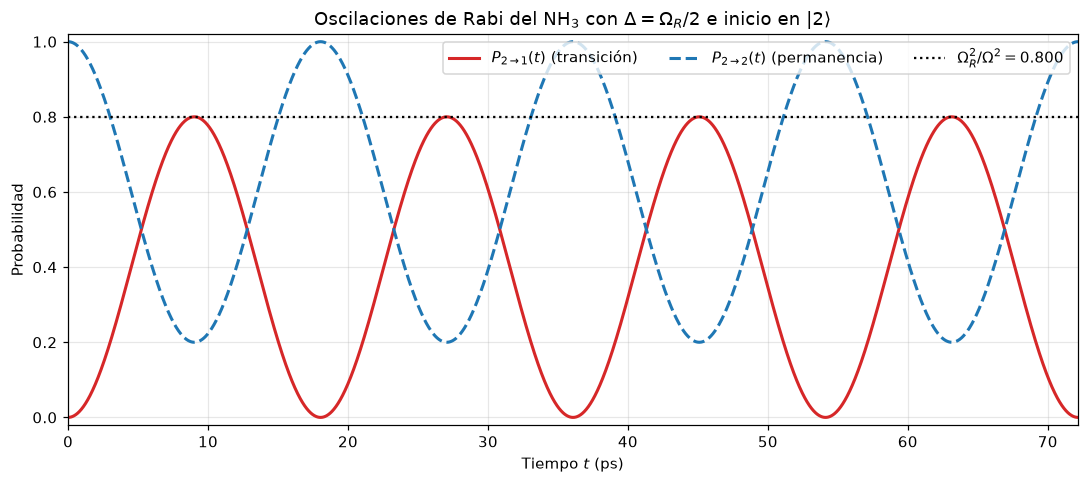

In [3]:
# ============================================================
# Probabilidades si el estado inicial es |2>
# ============================================================
def probabilidades_desde_2(t, Omega_R, Delta):
    # Devuelve P(2→1) y P(2→2) para un sistema que inicia en |2>.
    Omega = np.sqrt(Omega_R**2 + Delta**2)
    sin2 = np.sin(Omega * t)**2
    P_2a1 = (Omega_R / Omega)**2 * sin2
    P_2a2 = 1.0 - P_2a1
    return P_2a1, P_2a2


# Cuatro períodos de la probabilidad de ocupación: T_pop = π/Ω
t = np.linspace(0, 4 * np.pi / Omega, 4000)
P_2a1, P_2a2 = probabilidades_desde_2(t, Omega_R, Delta)
t_ps = t * 1e12

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(t_ps, P_2a1, color='tab:red', lw=2,
        label=r'$P_{2\to1}(t)$ (transición)')
ax.plot(t_ps, P_2a2, color='tab:blue', lw=2, ls='--',
        label=r'$P_{2\to2}(t)$ (permanencia)')
ax.axhline(amplitud_max, color='k', ls=':', lw=1.5,
           label=fr'$\Omega_R^2/\Omega^2 = {amplitud_max:.3f}$')

ax.set_xlabel(r'Tiempo $t$ (ps)')
ax.set_ylabel('Probabilidad')
ax.set_title(r'Oscilaciones de Rabi del NH$_3$ con $\Delta=\Omega_R/2$ e inicio en $|2\rangle$')
ax.set_xlim(t_ps[0], t_ps[-1])
ax.set_ylim(-0.02, 1.02)
ax.legend(loc='upper right', ncol=3)
fig.tight_layout()
plt.show()


In [4]:
# Verificación numérica del primer máximo de P(2→1)
t_max = np.pi / (2 * Omega)          # T_pop / 4
P_max = (Omega_R / Omega)**2 * np.sin(Omega * t_max)**2

print(f'Primer máximo en t = T_pop/4 = {t_max*1e12:.3f} ps')
print(f'P(2→1) en ese instante       = {P_max:.4f}')
print(f'P(2→2) en ese instante       = {1 - P_max:.4f}')


Primer máximo en t = T_pop/4 = 9.020 ps
P(2→1) en ese instante       = 0.8000
P(2→2) en ese instante       = 0.2000


### 3. Comparación con el caso resonante

Para visualizar el efecto de la desintonización, se compara la transición $|2\rangle\to|1\rangle$ del caso $\Delta=\Omega_R/2$ con el caso resonante $\Delta=0$. En resonancia la amplitud es 1 y la frecuencia es $\Omega_R$; con desintonización la amplitud baja a 0.8 y la oscilación es más rápida.


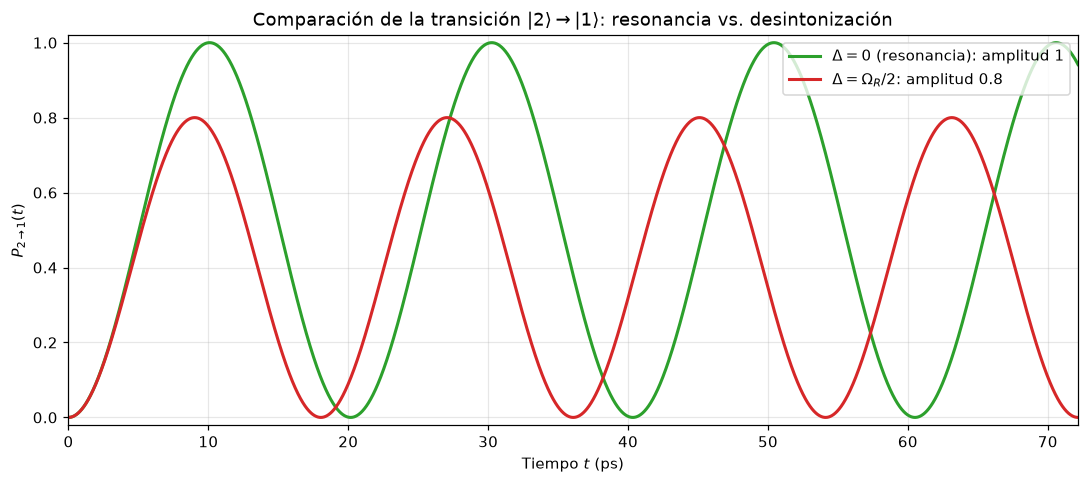

In [5]:
# Caso resonante: Δ = 0  ->  Ω = Ω_R
P_res = np.sin(Omega_R * t)**2

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(t_ps, P_res, color='tab:green', lw=2,
        label=r'$\Delta=0$ (resonancia): amplitud 1')
ax.plot(t_ps, P_2a1, color='tab:red', lw=2,
        label=r'$\Delta=\Omega_R/2$: amplitud 0.8')
ax.set_xlabel(r'Tiempo $t$ (ps)')
ax.set_ylabel(r'$P_{2\to1}(t)$')
ax.set_title(r'Comparación de la transición $|2\rangle\to|1\rangle$: resonancia vs. desintonización')
ax.set_xlim(t_ps[0], t_ps[-1])
ax.set_ylim(-0.02, 1.02)
ax.legend(loc='upper right')
fig.tight_layout()
plt.show()


## Resultados y conclusiones

- La frecuencia de Rabi del NH$_3$ es

$$
f_R=\frac{\Omega_R}{2\pi}=24.79\ \text{GHz},
\qquad
\Omega_R=2\pi(24.79\ \text{GHz})=1.558\times10^{11}\ \text{rad/s}.
$$

- El desdoblamiento de energía correspondiente es

$$
\Delta E=hf_R=1.643\times10^{-23}\ \text{J}=1.025\times10^{-4}\ \text{eV}.
$$

- La desintonización pedida es $\Delta=\Omega_R/2$, es decir, $f_\Delta=12.395$ GHz.

- La frecuencia de Rabi generalizada es

$$
\Omega=\sqrt{\Omega_R^{2}+\Delta^{2}}=\frac{\sqrt{5}}{2}\Omega_R,
\qquad
f_\Omega=27.72\ \text{GHz}.
$$

El período de la probabilidad de ocupación es

$$
T_{\rm pop}=\frac{\pi}{\Omega}=\frac{1}{2f_\Omega}=18.04\ \text{ps}.
$$

En la convención estándar de Rabi, el mismo resultado se escribe con $T=2\pi/\Omega=1/f_\Omega=36.08$ ps.

- Como el estado inicial es $|2\rangle$, $P_{2\to1}(t)$ parte de cero y alcanza un máximo de **0.8**; $P_{2\to2}(t)$ parte de uno y disminuye hasta **0.2**. La desintonización impide la inversión completa de la población.

- En el caso resonante ($\Delta=0$) la amplitud sería 1, $f_R=24.79$ GHz y el período de la probabilidad sería $T_{\rm pop,R}=\pi/\Omega_R=1/(2f_R)=20.17$ ps, es decir, habría oscilación completa entre $|1\rangle$ y $|2\rangle$.

- Físicamente, estas oscilaciones están asociadas al túnel cuántico del nitrógeno a través del plano de los hidrógenos. La frecuencia de 24.79 GHz coincide con la frecuencia del máser de amoníaco.
